# 01 · Outcome Data (Phase P2, part 1)

**Goal:** build one tidy **outcome panel** (country × series × year) that the boom catalogue (notebook 02)
will date takeoffs on. This follows `PREREGISTRATION.md` §1, which was frozen before this data was assembled.

| Section | Sector group | Source |
|---|---|---|
| 1 | Fintech | IMF Financial Access Survey (harmonised, % of GDP) |
| 2 | Fintech (rails) | Central-bank payment statistics: Malaysia (BNM), Philippines (BSP) |
| 3 | Digital sectors | e-Conomy SEA country reports 2021–2025, transcribed by hand (`data/public/manual/`) |
| 4 | Crypto | Chainalysis adoption ranks; CoinGecko exchange founding years (Orbis pending) |
| 5 | Assemble the panel and list issues for review |

**No driver data is used in this notebook.** Outcomes and drivers are only linked after the
boom catalogue is frozen (pre-registration "rule of order").

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from drivers.config import COUNTRIES, TIER_A, NAME, IMF_FAS_INDICATORS, RAW, PROC, FIG, ROOT
from drivers import fetch
warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)

MANUAL = ROOT / "data" / "public" / "manual"
SEA = list(COUNTRIES)
gdp = fetch.fetch_imf_weo_gdp().set_index(["iso3", "year"]).gdp_usd_b
wb = fetch.fetch_worldbank()
pop = wb[wb.indicator == "population"].set_index(["iso3", "year"]).value
kids = wb[wb.indicator == "children_0_14_pct"].set_index(["iso3", "year"]).value
adults = (pop * (1 - kids / 100)).rename("adults")
panel = []          # rows: iso3, group, series, year, value, unit, source, is_estimate

def add(df, group, series, unit, source, est_col=None):
    for _, r in df.iterrows():
        panel.append(dict(iso3=r.iso3, group=group, series=series, year=int(r.year), value=float(r.value),
                          unit=unit, source=source, is_estimate=bool(r[est_col]) if est_col else False))

## 1 · Fintech: IMF Financial Access Survey
Two pre-registered series, both as % of GDP:
* **mobile-money transaction value** (e-wallets, mobile money operators)
* **mobile & internet banking transaction value** (bank apps)

A country whose series is **zero or missing in every year** is excluded for that series. Zero there means
"not reported / not applicable", not "no boom". Zeros *before* activity starts are kept, because they are
real pre-launch values and matter for dating a takeoff.

In [2]:
fas = fetch.fetch_imf_fas()
fas = fas[fas.iso3.isin(SEA)].dropna(subset=["value"])
FAS_SERIES = {"mobile_money_tx_value_pct_gdp": "fas_mobile_money", "mobile_internet_banking_tx_value_pct_gdp": "fas_mobile_banking"}
fas_kept = []
for ind, series in FAS_SERIES.items():
    d = fas[fas.indicator == ind]
    for c, g in d.groupby("iso3"):
        if (g.value.fillna(0) == 0).all():
            continue
        add(g, "fintech", series, "% of GDP", "IMF FAS")
        fas_kept.append(dict(series=series, iso3=c, first=g.year.min(), last=g.year.max(), n_years=g.year.nunique()))
fas_kept = pd.DataFrame(fas_kept)
fas_kept.assign(country=fas_kept.iso3.map(NAME)).pivot(index="country", columns="series", values="n_years").fillna(0).astype(int)

series,fas_mobile_banking,fas_mobile_money
country,,
Cambodia,3,17
Indonesia,13,19
Malaysia,13,7
Myanmar,3,7
Philippines,7,15
Thailand,16,11
Timor-Leste,0,1
Vietnam,11,2


## 2 · Fintech rails: central-bank statistics
**Malaysia (BNM):** `T3 - Payment Systems` gives annual and monthly volume/value for **RPP** (the Real-time
Retail Payments Platform behind DuitNow), and `T2` gives **e-money** transactions. BNM redefined these tables
in July 2022, and the current files start in **2019**.

**Philippines (BSP):** InstaPay (2018–) and PESONet (2017–). BSP's server blocks script downloads, so the
monthly table is extracted with TinyFish into `data/public/manual/phl_instapay_monthly.csv`. If that file is
missing, the series is skipped and flagged below.

In [3]:
def bnm_annual(file, block_header_row=3, label_row=5):
    d = pd.read_excel(RAW / "central_banks" / "MYS" / file, sheet_name=0, header=None)
    years = d[d[1].astype(str).str.fullmatch(r"20\d\d")]
    return d, years

t3, t3y = bnm_annual("T3_-_Payment_Systems.xlsx")
hdr = t3.iloc[3].ffill(); sub = t3.iloc[4]
rpp_vol_col = [i for i in range(len(hdr)) if str(hdr[i]).startswith("RPP") and sub[i] == "Volume"][0]
rpp_val_col = rpp_vol_col + 1
rpp = pd.DataFrame(dict(iso3="MYS", year=t3y[1].astype(int), volume_mil=t3y[rpp_vol_col].astype(float),
                        value_rm_bil=t3y[rpp_val_col].astype(float)))
rpp = rpp.merge(adults.reset_index(), on=["iso3", "year"], how="left")
rpp["adults"] = rpp.adults.ffill()                                   # latest WB population carried forward for 2025
rpp["value"] = rpp.volume_mil * 1e6 / rpp.adults
add(rpp, "fintech", "rail_duitnow_rpp", "transactions per adult", "BNM T3")

t2, t2y = bnm_annual("T2_-_Payment_Instruments.xlsx")
hdr2 = t2.iloc[3].ffill(); sub2 = t2.iloc[5]
em_vol_col = [i for i in range(len(hdr2)) if str(hdr2[i]).startswith("E-money") and sub2[i] == "Volume"][0]
emoney = pd.DataFrame(dict(iso3="MYS", year=t2y[1].astype(int), volume_mil=t2y[em_vol_col].astype(float)))
emoney = emoney.merge(adults.reset_index(), on=["iso3", "year"], how="left")
emoney["adults"] = emoney.adults.ffill()
emoney["value"] = emoney.volume_mil * 1e6 / emoney.adults
add(emoney, "fintech", "rail_mys_emoney", "transactions per adult", "BNM T2")
print("Malaysia RPP/DuitNow and e-money, transactions per adult:")
display(pd.concat([rpp.set_index("year").value.rename("rpp_duitnow"), emoney.set_index("year").value.rename("e_money")], axis=1).round(1))

instapay_file = MANUAL / "phl_instapay_monthly.csv"
if instapay_file.exists():
    ip = pd.read_csv(instapay_file, parse_dates=["month"])
    ip_y = ip.groupby(ip.month.dt.year).agg(volume=("volume", "sum"), months=("volume", "size")).reset_index().rename(columns={"month": "year"})
    ip_y = ip_y[ip_y.months == 12]                                   # full years only
    ip_y["iso3"] = "PHL"
    ip_y = ip_y.merge(adults.reset_index(), on=["iso3", "year"], how="left"); ip_y["adults"] = ip_y.adults.ffill()
    ip_y["value"] = ip_y.volume / ip_y.adults
    add(ip_y, "fintech", "rail_instapay", "transactions per adult", "BSP via TinyFish")
    print("InstaPay full years:", ip_y.year.tolist())
else:
    print("⚠ InstaPay monthly file not available yet; series skipped")

Malaysia RPP/DuitNow and e-money, transactions per adult:


,rpp_duitnow,e_money
year,,
2019,4.3,82.8
2020,22.1,70.9
2021,40.3,80.3
2022,53.7,119.0
2023,76.6,147.4
2024,125.0,180.7
2025,192.1,225.1


⚠ InstaPay monthly file not available yet; series skipped


## 3 · Digital sectors: e-Conomy SEA (chain-linked)
The country reports were transcribed by hand from the chart images, 30 PDFs in all
(`econsea_levels.csv`: 360 levels; `econsea_growth_labels.csv`: 216 printed growth rates). All 216 printed
growth rates agree with the printed levels within rounding (check below), which confirms the transcription.

**Problem found:** editions revise earlier years, sometimes heavily (e.g. Indonesia 2019 online travel: $10.1B
in the 2021 edition, $7B in 2022). Taking "the newest edition's number for each year" splices different
methods into one series and creates jumps that aren't real.

**Fix (logged as a deviation):** **chain-linking**, the standard national-accounts practice.
1. Anchor on the newest **actual** level (2024, from the 2025 edition).
2. Go backwards with the **growth rate for each year-pair from the newest edition that reports it**. Printed
   growth labels are used, because they are more precise than integer-rounded levels.
3. The 2025 value (an H1-annualised **estimate**) is added forward and flagged.

The "newest-edition levels" version is kept for comparison.

In [4]:
lv = pd.read_csv(MANUAL / "econsea_levels.csv")
gr = pd.read_csv(MANUAL / "econsea_growth_labels.csv")

# transcription check: each printed growth label must fit the printed levels after rounding
k = ["edition", "iso3", "sector"]
m = gr.merge(lv[k + ["year", "gmv_usd_b"]].rename(columns={"year": "from_year", "gmv_usd_b": "v0"}), on=k + ["from_year"]) \
      .merge(lv[k + ["year", "gmv_usd_b"]].rename(columns={"year": "to_year", "gmv_usd_b": "v1"}), on=k + ["to_year"])
half = lambda v: np.where(v != v.round(0), 0.05, 0.5)
n = m.to_year - m.from_year
lo = (((m.v1 - half(m.v1)) / (m.v0 + half(m.v0))) ** (1 / n) - 1) * 100
hi = (((m.v1 + half(m.v1)) / (m.v0 - half(m.v0))) ** (1 / n) - 1) * 100
print(f"growth labels consistent with levels: {((m.pct >= lo - 1) & (m.pct <= hi + 1)).sum()} / {len(m)}")

def chain_link(iso3, sector):
    L = lv[(lv.iso3 == iso3) & (lv.sector == sector)]
    G = gr[(gr.iso3 == iso3) & (gr.sector == sector)]
    def g(y0, y1):
        """growth y0->y1 from the newest edition: printed yoy label first, else ratio of that edition's levels."""
        lab = G[(G.from_year == y0) & (G.to_year == y1) & (G.kind == "yoy")].sort_values("edition")
        if len(lab): return lab.pct.iloc[-1] / 100, int(lab.edition.iloc[-1]), "label"
        for e in sorted(L.edition.unique(), reverse=True):
            a, b = L[(L.edition == e) & (L.year == y0)], L[(L.edition == e) & (L.year == y1)]
            if len(a) and len(b): return b.gmv_usd_b.iloc[0] / a.gmv_usd_b.iloc[0] - 1, int(e), "levels"
        return None
    anchor = L[(L.edition == 2025) & (L.year == 2024)].gmv_usd_b.iloc[0]
    out = {2024: (anchor, False, "anchor 2025 ed.")}
    for y in range(2024, 2020, -1):                                  # back to 2020
        gg, e, how = g(y - 1, y)
        out[y - 1] = (out[y][0] / (1 + gg), False, f"{how} {e} ed.")
    # 2019: the 2022 edition's 2019->2021 CAGR combined with 2020->2021, else the 2021 edition's level ratio
    c = G[(G.from_year == 2019) & (G.to_year == 2021) & (G.kind == "cagr")].sort_values("edition")
    if len(c):
        g21 = out[2021][0] / out[2020][0] - 1
        out[2019] = (out[2021][0] / (1 + c.pct.iloc[-1] / 100) ** 2, False, "cagr 2022 ed.")
        # implied 2019->2020 = (1+cagr)^2 / (1+g2021) - 1 ; kept implicitly by the levels above
    else:
        gg, e, how = g(2019, 2020); out[2019] = (out[2020][0] / (1 + gg), False, f"{how} {e} ed.")
    gg, e, how = g(2024, 2025)
    out[2025] = (out[2024][0] * (1 + gg), True, f"{how} {e} ed. (H1-annualised estimate)")
    return pd.DataFrame([dict(iso3=iso3, sector=sector, year=y, gmv_usd_b=v, is_estimate=est, basis=b)
                         for y, (v, est, b) in sorted(out.items())])

chained = pd.concat([chain_link(c, s) for c in TIER_A for s in lv.sector.unique()], ignore_index=True)
latest = (lv.sort_values("edition").groupby(["iso3", "sector", "year"]).tail(1)
            .rename(columns={"gmv_usd_b": "gmv_latest"})[["iso3", "sector", "year", "gmv_latest"]])
chained = chained.merge(latest, on=["iso3", "sector", "year"], how="left")
chained = chained.merge(gdp.rename("gdp_usd_b").reset_index(), on=["iso3", "year"], how="left")
chained["value"] = chained.gmv_usd_b / chained.gdp_usd_b * 100            # GMV as % of GDP (pre-registered scaling)
for s, d in chained.groupby("sector"):
    add(d, "digital", f"econsea_{s}", "GMV % of GDP", "e-Conomy SEA (chain-linked)", est_col="is_estimate")
chained.to_parquet(PROC / "econsea_chained.parquet")
chained.pivot_table(index=["iso3", "sector"], columns="year", values="gmv_usd_b").round(1)

growth labels consistent with levels: 216 / 216


year                 2019  2020  2021  2022  2023  2024  2025
iso3 sector                                                  
IDN  ecommerce       25.0  31.7  48.3  57.9  58.5  62.0  70.7
     online_media     3.3   4.2   6.1   6.5   6.8   8.0   9.3
     online_travel    6.5   1.5   2.0   3.3   6.9   8.0   8.9
     transport_food   5.9   5.2   7.0   8.1   7.8   9.0  10.2
MYS  ecommerce        3.4   7.8  13.2  13.7  13.7  17.0  20.6
     online_media     1.5   2.0   2.3   2.4   2.8   3.0   3.4
     online_travel    6.2   1.1   1.1   2.8   6.6   9.0  10.7
     transport_food   1.3   1.6   2.1   2.9   3.5   4.0   4.5
PHL  ecommerce        2.6   5.0  11.6  15.0  17.1  20.0  23.2
     online_media     1.5   1.8   2.5   2.7   3.3   4.0   4.6
     online_travel    3.3   0.4   0.6   1.8   3.2   4.0   4.6
     transport_food   0.9   1.1   1.6   2.1   2.5   3.0   3.6
SGP  ecommerce        2.2   5.1   7.4   7.6   7.1   8.0   8.2
     online_media     1.6   1.9   2.2   2.5   2.8   3.0   3.4
     online_travel    6.3   1.4   1.8   5.1  10.4  11.0  11.7
     transport_food   2.2   2.1   2.8   3.8   4.7   5.0   5.6
THA  ecommerce        5.1  12.0  20.2  20.0  21.8  27.0  32.9
     online_media     2.7   3.4   4.4   4.5   5.5   6.0   6.5
     online_travel    7.6   1.9   2.1   2.8   7.7  11.0  11.7
     transport_food   0.9   1.8   2.4   2.6   3.0   4.0   4.6
VNM  ecommerce        5.0   7.0  10.8  14.7  18.4  21.0  24.6
     online_media     2.6   2.9   3.8   4.3   4.6   5.0   5.8
     online_travel    2.7   0.9   0.5   1.5   2.5   3.0   3.5
     transport_food   1.3   1.7   2.4   2.9   3.3   4.0   4.8

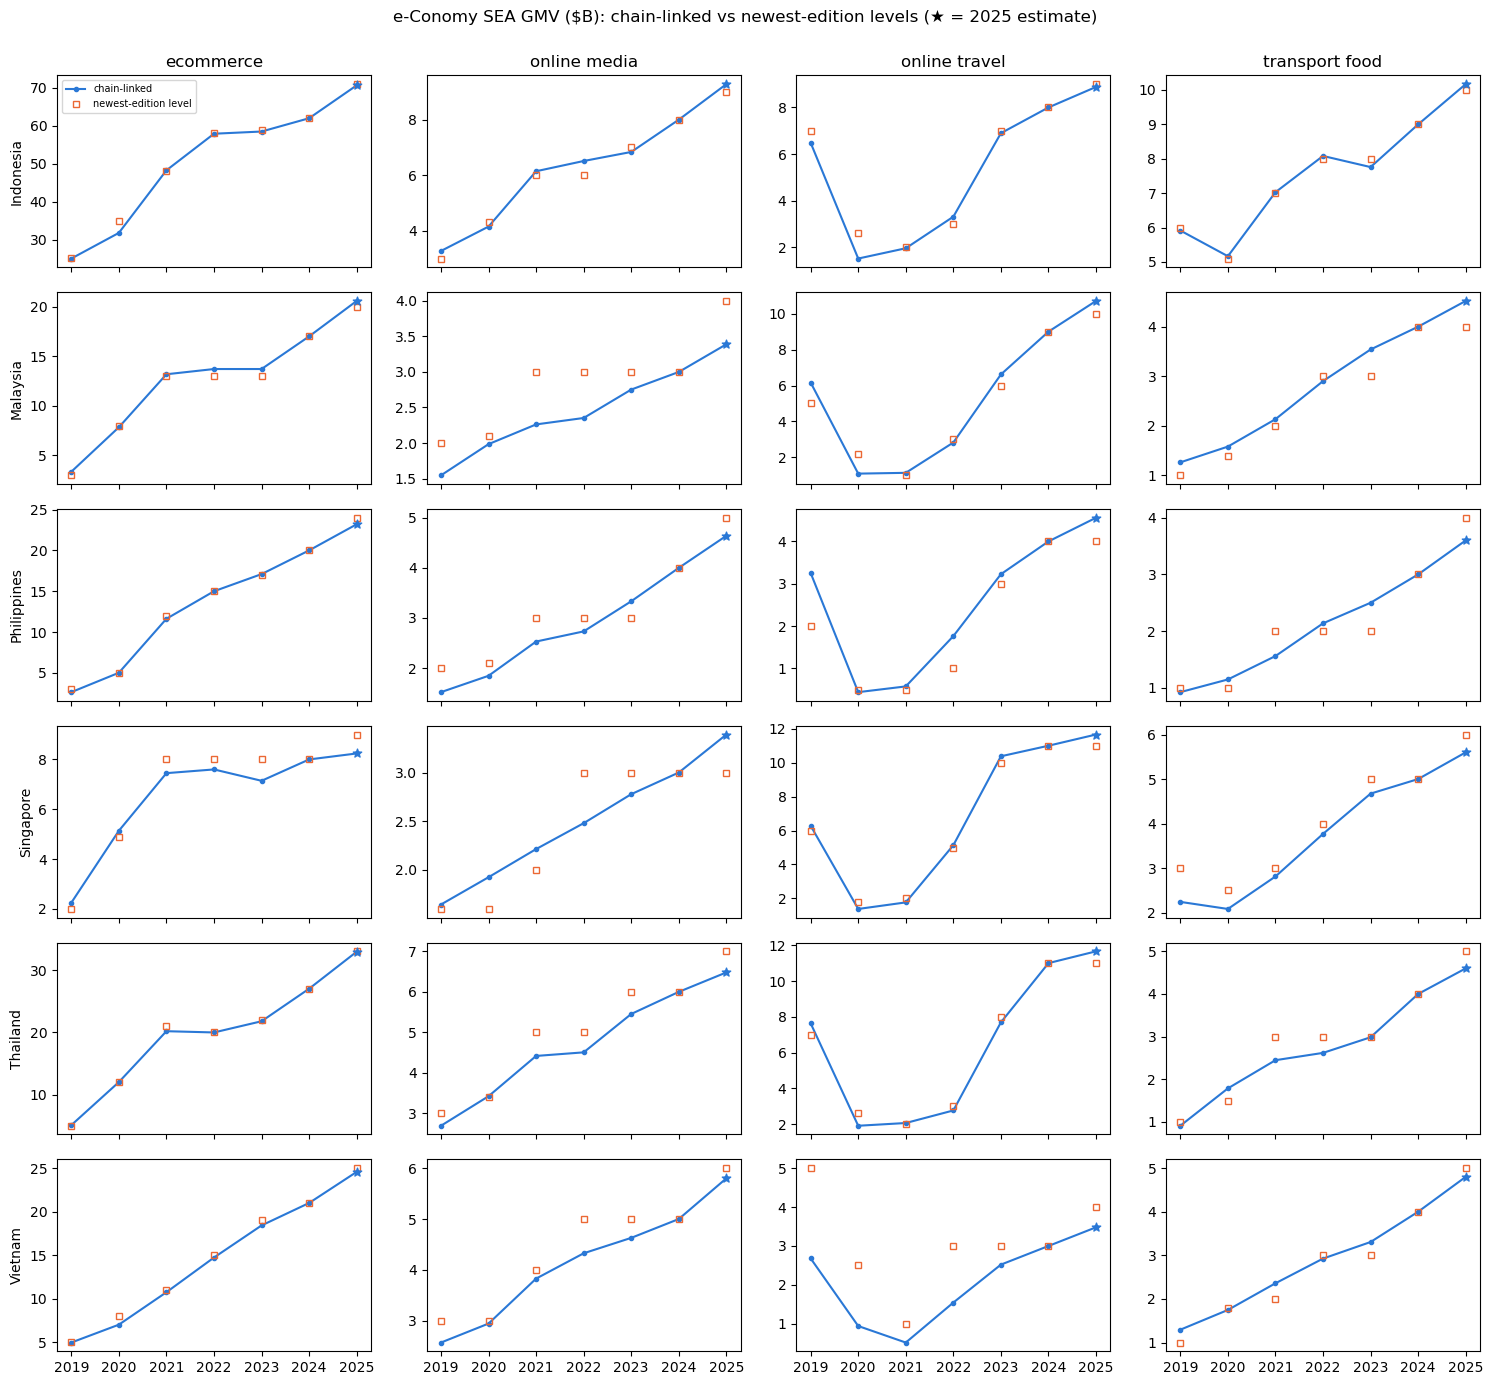

In [5]:
fig, axes = plt.subplots(len(TIER_A), 4, figsize=(15, 2.3 * len(TIER_A)), sharex=True)
for i, c in enumerate(TIER_A):
    for j, s in enumerate(sorted(lv.sector.unique())):
        d = chained[(chained.iso3 == c) & (chained.sector == s)]
        ax = axes[i, j]
        ax.plot(d.year, d.gmv_usd_b, "-o", ms=3, color="#2a78d6", label="chain-linked")
        ax.plot(d.year, d.gmv_latest, "s", ms=4, mfc="none", color="#eb6834", label="newest-edition level")
        ax.scatter(d.year[d.is_estimate], d.gmv_usd_b[d.is_estimate], s=40, marker="*", color="#2a78d6", zorder=5)
        if i == 0: ax.set_title(s.replace("_", " "))
        if j == 0: ax.set_ylabel(NAME[c])
axes[0, 0].legend(fontsize=7)
plt.suptitle("e-Conomy SEA GMV ($B): chain-linked vs newest-edition levels (★ = 2025 estimate)", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "01_econsea_chain_vs_latest.png", dpi=140); plt.show()

## 4 · Crypto
**Chainalysis Global Crypto Adoption Index.** Only top-20 ranks are published as text (2022–2026); 2020–2021
are images only. The **method changed almost every year** (P2P dropped in 2024, institutional added in 2025,
a completely new design in 2026). Ranks are kept **for description only**, never as a takeoff series.

**CoinGecko exchanges by founding year** count only exchanges that still exist (survivorship bias).
Firm formation for the pre-registered crypto outcome comes from the **Orbis export** (pending, via UCL).

In [6]:
ca = pd.read_csv(MANUAL / "chainalysis_ranks.csv")
display(ca[ca.index_variant == "overall"].pivot(index="iso3", columns="edition", values="overall_rank")
          .rename(index=NAME).fillna("—"))
cg = fetch.fetch_coingecko_exchanges()
name2iso = {v[0]: k for k, v in COUNTRIES.items()}
cg_sea = cg[cg.country.isin(name2iso)].assign(iso3=lambda d: d.country.map(name2iso))
print("SEA-headquartered exchanges still listed by CoinGecko, by founding year:")
cg_sea.pivot_table(index="year_established", columns="iso3", values="id", aggfunc="count").fillna(0).astype(int)

edition,2022,2023,2024,2025,2026
iso3,,,,,
Indonesia,20.0,7.0,3.0,7.0,14.0
Cambodia,—,—,17.0,—,—
Philippines,2.0,6.0,8.0,9.0,19.0
Thailand,8.0,10.0,16.0,17.0,8.0
Vietnam,1.0,3.0,5.0,4.0,18.0


SEA-headquartered exchanges still listed by CoinGecko, by founding year:


iso3,IDN,MYS,PHL,SGP,THA,VNM
year_established,,,,,,
2013.0,0,0,0,1,0,0
2014.0,1,0,1,0,0,0
2017.0,1,0,0,0,1,0
2018.0,2,0,0,2,1,0
2019.0,0,0,0,0,0,1
2020.0,0,0,0,2,0,0
2021.0,0,0,0,10,1,0
2022.0,1,0,0,0,0,0
2023.0,0,1,0,3,0,0


### 4b · Firm formation from Orbis (UCL-licensed)
New crypto/blockchain and fintech companies per year by country, by **date of incorporation**, from the Orbis
company register (keyword search on business descriptions, PREREGISTRATION.md §8).

**Bias check:** the search summary of the current exports shows two filters that were not in the specification:
1. **"Status: Active companies, Unknown situation"**: closed companies are excluded (survivorship bias)
2. **"Exclude companies with no recent financial data"**: young firms without filed accounts are excluded

The counts below are therefore **preliminary**. They are stored separately in `data/licensed/derived/`, outside the
coded outcome panel, and are not dated with the takeoff rule until a corrected export arrives.

In [7]:
import re
LIC = ROOT / "data" / "licensed"
iso2to3 = {v[1]: k for k, v in COUNTRIES.items()}
firm_rows, bias = [], {}
for kind in ["crypto", "fintech"]:
    f = LIC / "orbis" / f"Orbis_{kind}.xlsx"
    if not f.exists():
        print(f"⚠ {f.name} missing"); continue
    summ = pd.read_excel(f, sheet_name="Search summary", header=None, engine="calamine").astype(str)
    text = " ".join(summ.values.ravel())
    bias[kind] = dict(active_only="Active companies" in text and "Inactive" not in text,
                      excludes_no_recent_financials="Exclude companies with no recent financial data" in text)
    r = pd.read_excel(f, sheet_name="Results", engine="calamine").dropna(subset=["Company name Latin alphabet"])
    r["iso3"] = r["Country ISO code"].map(iso2to3)
    r["inc_year"] = pd.to_datetime(r["Date of incorporation"], errors="coerce").dt.year
    r = r.dropna(subset=["iso3", "inc_year"])
    cnt = r[r.inc_year.between(2005, 2025)].groupby(["iso3", "inc_year"]).size().rename("new_firms").reset_index()
    full = pd.MultiIndex.from_product([sorted(r.iso3.unique()), range(2005, 2026)], names=["iso3", "inc_year"])
    cnt = cnt.set_index(["iso3", "inc_year"]).reindex(full, fill_value=0).reset_index().rename(columns={"inc_year": "year"})
    cnt = cnt.merge(pop.rename("population").reset_index(), on=["iso3", "year"], how="left")
    cnt["population"] = cnt.groupby("iso3").population.ffill()
    cnt["new_per_million"] = cnt.new_firms / cnt.population * 1e6
    cnt["stock_per_million"] = cnt.groupby("iso3").new_firms.cumsum() / cnt.population * 1e6
    cnt["kind"] = kind
    firm_rows.append(cnt)
firms = pd.concat(firm_rows, ignore_index=True)
(LIC / "derived").mkdir(exist_ok=True)
firms.to_parquet(LIC / "derived" / "orbis_firm_formation_PRELIMINARY.parquet")
print("export filters found:", bias)
firms.groupby(["kind", "iso3"]).new_firms.sum().unstack(0).fillna(0).astype(int).rename(index=NAME)

export filters found: {'crypto': {'active_only': True, 'excludes_no_recent_financials': True}, 'fintech': {'active_only': True, 'excludes_no_recent_financials': True}}


kind,crypto,fintech
iso3,,
Indonesia,20,28
Cambodia,0,264
Laos,0,3
Myanmar,0,3
Malaysia,178,574
Philippines,5,36
Singapore,217,204
Thailand,22,43
Vietnam,105,51


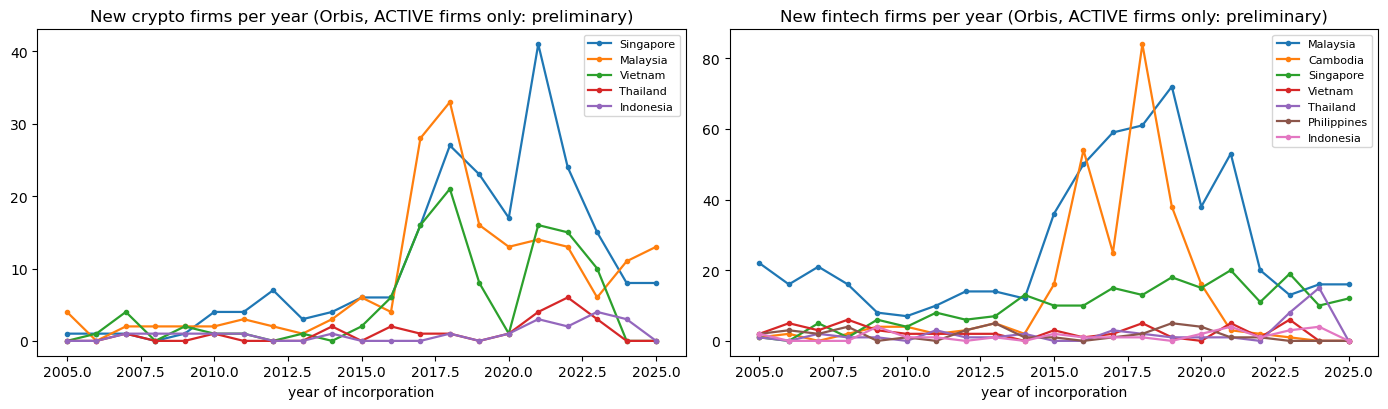

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, kind in zip(axes, ["crypto", "fintech"]):
    d = firms[firms.kind == kind]
    keep = d.groupby("iso3").new_firms.sum().sort_values(ascending=False)
    for c in keep[keep >= 20].index:
        g = d[d.iso3 == c]
        ax.plot(g.year, g.new_firms, "-o", ms=3, lw=1.6, label=NAME[c])
    ax.set_title(f"New {kind} firms per year (Orbis, ACTIVE firms only: preliminary)")
    ax.legend(fontsize=8); ax.set_xlabel("year of incorporation")
plt.tight_layout(); plt.savefig(FIG / "01_orbis_firm_formation_preliminary.png", dpi=150); plt.show()

### 4c · Euromonitor Passport: online food ordering (UCL-licensed)
A first export held total foodservice (not usable). The second export is **"Consumer Foodservice Online Ordering"**
(retail value, current prices, local currency). Euromonitor tracks it only from **2020**, so it cannot push food
delivery back before 2019. It does add two things e-Conomy SEA lacks:
1. **food delivery on its own**: e-Conomy only reports transport and food combined
2. an **independent cross-check** on the e-Conomy numbers

Scaled to % of GDP with World Bank local-currency GDP. Stored in `data/licensed/derived/` (licensed source).

In [9]:
pf = sorted((LIC / "passport").glob("Passport_Stats_*.xls*"))
wb_lcu = wb[wb.indicator == "gdp_lcu"].set_index(["iso3", "year"]).value / 1e9
name2iso = {v[0]: k for k, v in COUNTRIES.items()}
pass_rows = []
for f in pf:
    d = pd.read_excel(f, header=None, engine="xlrd" if f.suffix == ".xls" else "calamine")
    hdr = d.index[d[0].astype(str).str.strip() == "Geography"][0]
    yrs = [int(y) for y in d.loc[hdr, 5:].dropna().tolist()]
    for _, r in d.loc[hdr + 1:].iterrows():
        if r[0] not in name2iso or "Online Ordering" not in str(r[1]):
            continue
        scale = 1.0 if "billion" in str(r[3]) else 1e-3
        for y, v in zip(yrs, r.iloc[5:5 + len(yrs)].tolist()):
            pass_rows.append(dict(iso3=name2iso[r[0]], year=y, value_lcu_b=float(v) * scale, unit_raw=r[3]))
passport = pd.DataFrame(pass_rows)
passport["value"] = passport.apply(lambda r: r.value_lcu_b / wb_lcu.get((r.iso3, r.year), np.nan) * 100, axis=1)
passport["series"] = "passport_food_online_ordering"
passport.to_parquet(LIC / "derived" / "passport_food_online_ordering.parquet")
print("Online food ordering, % of GDP (Euromonitor Passport):")
display(passport.pivot(index="iso3", columns="year", values="value").rename(index=NAME).round(3))
tf = chained[chained.sector == "transport_food"].pivot(index="iso3", columns="year", values="value")
both = passport.pivot(index="iso3", columns="year", values="value")
yrs_common = [y for y in both.columns if y in tf.columns and y >= 2021]
g_p = both[yrs_common].pct_change(axis=1).iloc[:, 1:].stack(); g_e = tf[yrs_common].pct_change(axis=1).iloc[:, 1:].stack()
print(f"Year-on-year growth, Passport food vs e-Conomy transport+food (2022-25): correlation = {g_p.corr(g_e):.2f}")

Online food ordering, % of GDP (Euromonitor Passport):


year,2020,2021,2022,2023,2024,2025
iso3,,,,,,
Indonesia,0.459,0.472,0.420,0.349,0.365,0.380
Malaysia,0.312,0.601,0.638,0.665,0.622,0.593
Philippines,0.687,1.221,1.155,0.969,0.808,0.780
Singapore,0.569,0.658,0.466,0.453,0.415,0.431
Thailand,0.458,0.623,0.679,0.563,0.601,0.652
Vietnam,0.192,0.248,0.349,0.427,0.424,0.492


Year-on-year growth, Passport food vs e-Conomy transport+food (2022-25): correlation = 0.15


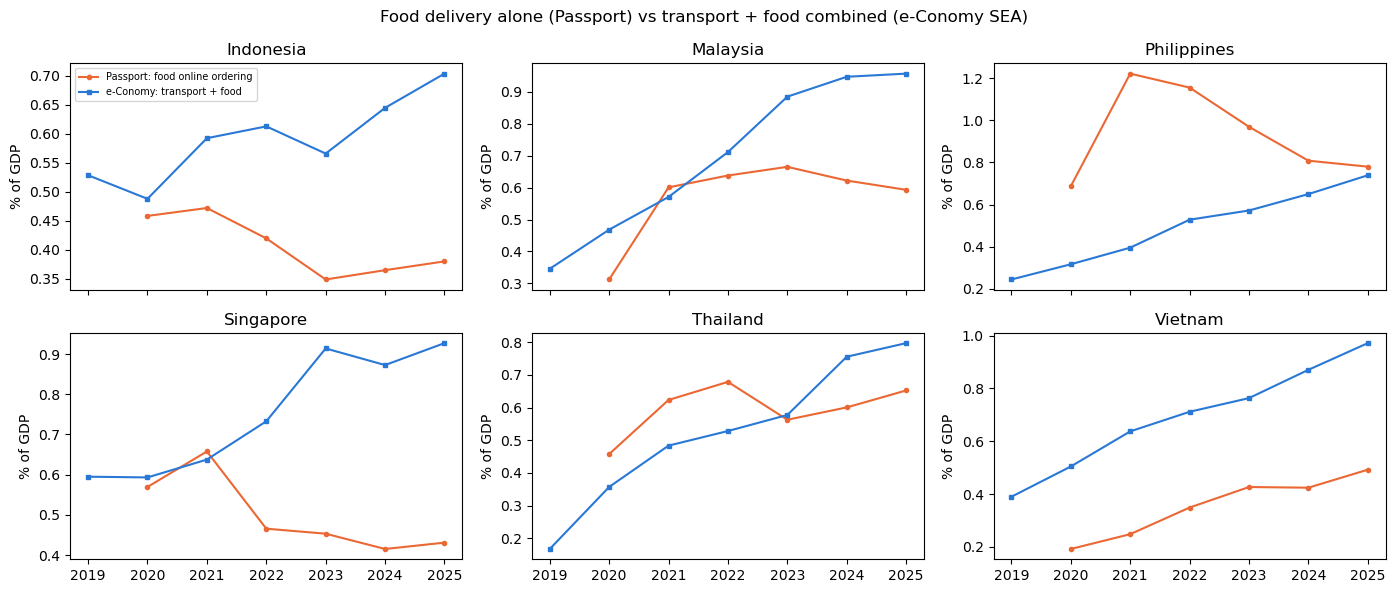

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, c in zip(axes.flat, ["IDN", "MYS", "PHL", "SGP", "THA", "VNM"]):
    p_ = passport[passport.iso3 == c]; e_ = chained[(chained.iso3 == c) & (chained.sector == "transport_food")]
    ax.plot(p_.year, p_.value, "-o", ms=3, color="#eb6834", label="Passport: food online ordering")
    ax.plot(e_.year, e_.value, "-s", ms=3, color="#2a78d6", label="e-Conomy: transport + food")
    ax.set_title(NAME[c]); ax.set_ylabel("% of GDP")
axes.flat[0].legend(fontsize=7)
plt.suptitle("Food delivery alone (Passport) vs transport + food combined (e-Conomy SEA)")
plt.tight_layout(); plt.savefig(FIG / "01_passport_vs_econsea_food.png", dpi=150); plt.show()

## 5 · Assemble the outcome panel

In [11]:
P = pd.DataFrame(panel)
P.to_parquet(PROC / "outcome_panel.parquet")
cov = (P[~P.is_estimate].groupby(["group", "series", "iso3"]).year.agg(["min", "max", "nunique"])
         .rename(columns={"nunique": "n_years"}).reset_index())
print(f"{len(P)} rows | {P.series.nunique()} series | {cov[['series','iso3']].drop_duplicates().shape[0]} country-series")
cov.assign(country=cov.iso3.map(NAME)).pivot(index="country", columns="series", values="n_years").fillna(0).astype(int)

327 rows | 8 series | 41 country-series


series,econsea_ecommerce,econsea_online_media,econsea_online_travel,econsea_transport_food,fas_mobile_banking,fas_mobile_money,rail_duitnow_rpp,rail_mys_emoney
country,,,,,,,,
Cambodia,0,0,0,0,3,17,0,0
Indonesia,6,6,6,6,13,19,0,0
Malaysia,6,6,6,6,13,7,7,7
Myanmar,0,0,0,0,3,7,0,0
Philippines,6,6,6,6,7,15,0,0
Singapore,6,6,6,6,0,0,0,0
Thailand,6,6,6,6,16,11,0,0
Timor-Leste,0,0,0,0,0,1,0,0
Vietnam,6,6,6,6,11,2,0,0


## 6 · Issues for the P2 review
| # | Issue | Proposed handling |
|---|---|---|
| 1 | **e-Conomy SEA editions revise past years** (e.g. Indonesia 2019 travel: 10.1 → 7) | Chain-link with the newest edition's growth rates (done; logged as a deviation) |
| 2 | **"Actual figures only"** leaves digital sectors with **6 years (2019–2024)**; 2025 is an H1-annualised estimate | Primary analysis follows the pre-registration (6 years); a sensitivity run includes 2025e |
| 3 | **Transport and food delivery are never labelled separately** in the country reports | Kept as one combined sector, `transport_food` |
| 4 | Most digital sectors were **already growing in 2019**, so takeoff probably happened before the data starts | The coding sheet adds a "before" option (left-censored); these series stay in the catalogue as "pre-2019 takeoff" |
| 5 | **BSP blocks script downloads** (InstaPay/PESONet) | TinyFish extraction attempted; if unavailable, the Philippines' rail series is missing, and IMF FAS still covers the Philippines' fintech outcome |
| 6 | **Chainalysis method changes almost every year**, and only top-20 ranks are public | Ranks used for description only, never for takeoff dating |
| 7 | **Orbis company exports exclude inactive firms and firms without recent financials** | Your decision: use as-is, with **survivorship bias** stated as a limitation wherever firm formation is used |
| 9 | **Passport online food ordering starts only in 2020** | Used as food-delivery-only series 2020–2025 and as a cross-check on e-Conomy; dated with the **frozen** digital rule (an out-of-sample test, no refitting) |
| 10 | **Indonesian firms are likely undercounted in Orbis** (English keyword search vs local-language descriptions) | Stated as a limitation |
| 8 | A fetch bug briefly duplicated IMF FAS rows (domestic currency + % of GDP under one code) | Fixed in `fetch.py` with a duplicate assertion; all notebooks rebuilt |